# 05 — Síntesis de atributos y micro-mercados

**La pregunta.** Cada propiedad tiene 29 atributos extraídos del aviso (amenities del
edificio, equipamiento de la unidad, estado), además de su tipo, tamaño, antigüedad y
disposición. ¿Se pueden resumir en pocos ejes que se lean? ¿Hay **tipos de propiedad**
(micro-mercados) que rinden distinto dentro del mismo barrio y tamaño?

**Cuándo vale la pena.** Que un método corra no alcanza. Para que la síntesis se
incorpore tiene que cumplir cuatro cosas:

1. **los ejes se leen**: cada uno tiene un nombre que el inversor entiende;
2. **agregan algo**: un eje que repite una variable que el dataset ya tiene no aporta
   información, solo otra forma de decir lo mismo;
3. **mejoran el modelo de alquiler** fuera de muestra en al menos
   `supuestos.MEJORA_MINIMA_R2` (0,01) en todas las semillas, el mismo criterio que se
   usó en el notebook 03 para las variables espaciales;
4. **los micro-mercados son estables** (no cambian con la muestra) y **separan algo que
   el barrio y el tamaño no separan**.

**Dos métodos.** PCA sobre las 29 dummies, como se había declarado, y MCA (análisis de
correspondencias múltiples) sobre las mismas más las cuatro categóricas de estructura. El
MCA está hecho para variables categóricas; el PCA sobre dummies es una aproximación. Si
los dos encuentran los mismos ejes, el resultado no depende del método.

Las piezas están en `src/sintesis.py`, y `src/test_sintesis.py` las verifica contra
scipy y contra estructuras plantadas.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import eda
import modelo_alquiler as M
import sintesis as SI
import supuestos as S

eda.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

P = "../data/processed"
df = pd.read_csv(f"{P}/dataset_analitico.csv", encoding="utf-8-sig", low_memory=False)
ok = (df["estimacion_confiable"] == 1) & df["rent_bruta_pct"].notna()
print(f"Avisos: {len(df):,} (venta y alquiler: los atributos describen la oferta). "
      f"Atributos: {len(SI.ATRIBUTOS)} dummies + {len(SI.ESTRUCTURA)} categoricas de estructura")

Avisos: 12,097 (venta y alquiler: los atributos describen la oferta). Atributos: 29 dummies + 4 categoricas de estructura


## 1. PCA sobre las 29 dummies

**Método.** Componentes principales de las 29 dummies estandarizadas. La carga de cada
dummy es su correlación con el componente. Una dummy no es continua, así que el
porcentaje de varianza de cada componente sale bajo por construcción: se mira cómo
cae, no su nivel.

In [2]:
pc = SI.pca_atributos(df)
var = pd.DataFrame({"varianza": pc["varianza"][:8], "acumulada": np.cumsum(pc["varianza"])[:8],
                    "autovalor": pc["autovalores"][:8]}, index=[f"CP{i + 1}" for i in range(8)])
print(f"Componentes con autovalor > 1 (criterio de Kaiser): {(pc['autovalores'] > 1).sum()} de {len(SI.ATRIBUTOS)}")
var.T

Componentes con autovalor > 1 (criterio de Kaiser): 7 de 29


,CP1,CP2,CP3,CP4,CP5,CP6,CP7,CP8
varianza,0.161,0.082,0.060,0.043,0.041,0.040,0.035,0.034
acumulada,0.161,0.242,0.302,0.346,0.387,0.427,0.462,0.496
autovalor,4.665,2.368,1.738,1.254,1.199,1.147,1.021,0.998


In [3]:
# Las dummies que definen cada componente: carga de 0,4 o mas, en valor absoluto.
for cp in ["CP1", "CP2", "CP3"]:
    c = pc["cargas"][cp]
    c = c[c.abs() >= 0.4].sort_values(key=abs, ascending=False)
    print(f"{cp}: " + ", ".join(f"{k} {v:+.2f}" for k, v in c.items()))

cp1 = pc["puntajes"][:, 0]
print(f"\nCorrelacion de CP1 con n_amenities (ya en el dataset): {np.corrcoef(cp1, df['n_amenities'])[0, 1]:+.3f}")

CP1: sum +0.74, solarium +0.73, pileta +0.71, gimnasio +0.67, laundry +0.56, parrilla +0.50, cochera_txt +0.49, ascensor +0.44, sauna +0.43, aire_acondicionado +0.42, balcon +0.40, losa_radiante +0.40
CP2: dependencia +0.62, lavadero +0.59, toilette +0.59, baulera +0.44
CP3: patio_jardin +0.63, parrilla +0.47, ascensor -0.47, terraza +0.45, balcon -0.40

Correlacion de CP1 con n_amenities (ya en el dataset): +0.963


**Lectura.** Siete componentes pasan el criterio de Kaiser, pero solo los tres primeros
tienen un nombre claro:

- **CP1, edificio con amenities** (16% de la varianza): pileta, SUM, solarium, gimnasio,
  laundry. Es casi exactamente `n_amenities`, el conteo que ya está en el dataset.
- **CP2, unidad grande de categoría** (8%): dependencia, toilette, lavadero, baulera,
  losa radiante.
- **CP3, PH o casa con patio** (6%): patio, parrilla y terraza, sin ascensor ni balcón.

A partir de CP4 las cargas se reparten y ningún componente se puede nombrar.

## 2. MCA: los mismos atributos, con el método para categóricas

**Método.** Análisis de correspondencias múltiples sobre 33 variables: las 29 dummies como
sí/no, más tipo de propiedad, tramo de superficie, tramo de antigüedad y disposición. La
inercia de cada eje se informa cruda y con la **corrección de Benzécri**: la cruda
subestima cuánto resume cada eje, porque la codificación disyuntiva infla la inercia
total.

In [4]:
tabla = SI.tabla_mca(df)
mc = SI.mca(tabla)
inercia = pd.DataFrame({"cruda": mc["autovalores"][:6] / mc["autovalores"].sum(),
                        "Benzecri": mc["benzecri"][:6]}, index=[f"D{i + 1}" for i in range(6)])
inercia["Benzecri acumulada"] = inercia["Benzecri"].cumsum()
inercia.T

,D1,D2,D3,D4,D5,D6
cruda,0.123,0.078,0.054,0.036,0.032,0.030
Benzecri,0.704,0.206,0.066,0.011,0.005,0.003
Benzecri acumulada,0.704,0.910,0.976,0.987,0.992,0.995


In [5]:
# Las categorias que mas contribuyen a cada eje, con el lado en que quedan.
for d in ["D1", "D2", "D3"]:
    top = mc["contribucion"][d].sort_values(ascending=False).head(8).index
    print(f"{d}: " + ", ".join(f"{t} ({mc['categorias'].loc[t, d]:+.1f})" for t in top))

F = mc["filas"]
ph_casa = df["tipo_familia"].isin(["ph", "casa"]).astype(float)
log_sup = df["log_sup"].fillna(df["log_sup"].median())
comparacion = pd.DataFrame([
    {"eje": "D1", "contra": "CP1 del PCA", "correlacion": np.corrcoef(F[:, 0], cp1)[0, 1]},
    {"eje": "D1", "contra": "n_amenities", "correlacion": np.corrcoef(F[:, 0], df["n_amenities"])[0, 1]},
    {"eje": "D2", "contra": "log de la superficie", "correlacion": np.corrcoef(F[:, 1], log_sup)[0, 1]},
    {"eje": "D3", "contra": "es PH o casa", "correlacion": np.corrcoef(F[:, 2], ph_casa)[0, 1]},
]).set_index(["eje", "contra"])
comparacion

D1: solarium=si (+1.8), sum=si (+1.6), pileta=si (+1.5), gimnasio=si (+2.1), laundry=si (+1.6), antiguedad_rango=1-5 (+1.2), parrilla=si (+0.7), sauna=si (+1.7)
D2: superficie_rango=120+ (+1.5), tipo_familia=casa (+2.0), dependencia=si (+1.4), toilette=si (+0.8), patio_jardin=si (+0.8), lavadero=si (+0.6), lavadero=no (-0.5), superficie_rango=36-55 (-0.7)
D3: tipo_familia=ph (+1.1), losa_radiante=si (-1.0), patio_jardin=si (+0.6), dependencia=si (-1.0), tipo_familia=casa (+1.4), balcon=no (+0.6), parrilla=si (+0.6), calefaccion=si (-0.7)


correlacion
eje contra                           
D1  CP1 del PCA                 0.988
    n_amenities                 0.947
D2  log de la superficie        0.864
D3  es PH o casa                0.561

### Gráfico 11 — ¿Qué separan los dos primeros ejes del MCA?

Cada punto es una categoría (por ejemplo "gimnasio" o "120+ m²"), ubicada según su
coordenada en los dos primeros ejes. Se rotulan las que más contribuyen a cada eje. Los
rombos son el centro de cada micro-mercado de la sección 3.

guardado: ../graficos\11_mca_mapa.png


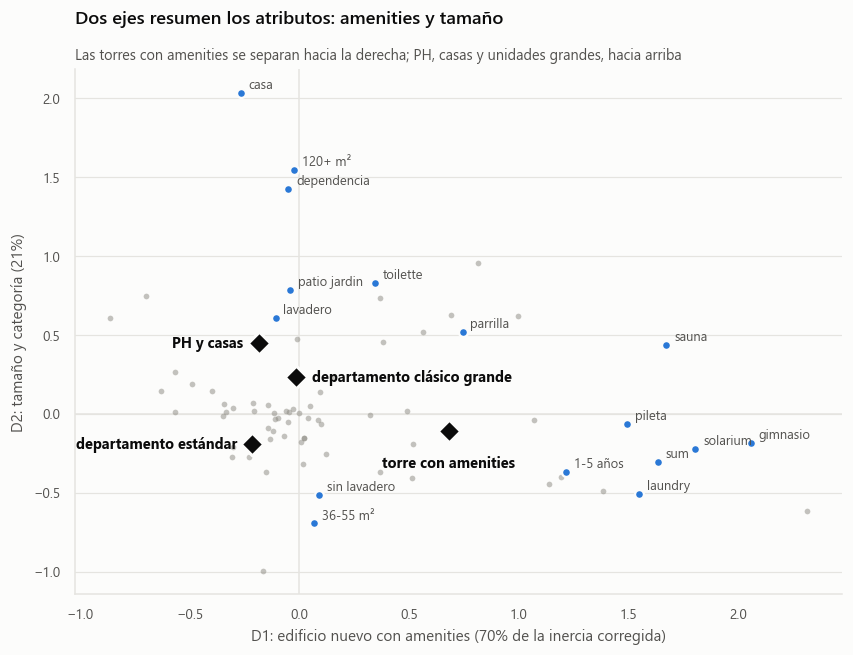

In [6]:
# Los micro-mercados se calculan aca para ubicar su centro en el mapa; la
# seccion 3 los analiza.
df = df.copy()   # el dataset tiene 128 columnas: sin copiar, pandas avisa que el frame esta fragmentado
df["grupo"] = SI.micromercados(F)
nombres = SI.nombrar(df)
df["micromercado"] = df["grupo"].map(nombres)
# Los nombres internos van sin tilde; en los graficos, con.
VISIBLE = {"departamento estandar": "departamento estándar", "departamento clasico grande": "departamento clásico grande"}


def etiqueta(cat):
    var, val = cat.split("=", 1)
    if var == "tipo_familia":
        return val
    if var == "superficie_rango":
        return f"{val} m²"
    if var == "antiguedad_rango":
        return f"{val} años" if val[0].isdigit() else val
    if var == "disposicion":
        return val
    nombre = var.replace("_txt", "").replace("_", " ")
    return nombre if val == "si" else f"sin {nombre}"


cat = mc["categorias"]
destacadas = set(mc["contribucion"]["D1"].nlargest(8).index) | set(mc["contribucion"]["D2"].nlargest(8).index)
centros = pd.DataFrame(F[:, :2], columns=["D1", "D2"]).groupby(df["micromercado"].values).mean()

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.axhline(0, color=eda.GRILLA, linewidth=1, zorder=0)
ax.axvline(0, color=eda.GRILLA, linewidth=1, zorder=0)
otras = cat.loc[~cat.index.isin(destacadas)]
ax.scatter(otras["D1"], otras["D2"], s=14, color=eda.TINTA_3, alpha=0.5, linewidth=0)
dest = cat.loc[sorted(destacadas)]
ax.scatter(dest["D1"], dest["D2"], s=34, color=eda.SERIE_1, edgecolor=eda.SUPERFICIE, linewidth=1.5, zorder=3)
for c, f in dest.iterrows():
    ax.annotate(etiqueta(c), (f["D1"], f["D2"]), xytext=(5, 3), textcoords="offset points", fontsize=8.5,
                color=eda.TINTA_2)
ax.scatter(centros["D1"], centros["D2"], s=110, marker="D", color=eda.TINTA, edgecolor=eda.SUPERFICIE,
           linewidth=2, zorder=4)
# Cada rotulo del lado donde no pisa a otro rombo.
lado = {"PH y casas": ((-10, 0), "right"), "departamento clasico grande": ((10, 0), "left"),
        "departamento estandar": ((-10, 0), "right"), "torre con amenities": ((0, -16), "center")}
for g, f in centros.iterrows():
    ax.annotate(VISIBLE.get(g, g), (f["D1"], f["D2"]), xytext=lado[g][0], textcoords="offset points",
                ha=lado[g][1], va="center" if lado[g][1] != "center" else "top", fontsize=9.5,
                color=eda.TINTA, fontweight="bold")
ax.set_xlabel(f"D1: edificio nuevo con amenities ({mc['benzecri'][0]:.0%} de la inercia corregida)")
ax.set_ylabel(f"D2: tamaño y categoría ({mc['benzecri'][1]:.0%})")
eda.titulo(ax, "Dos ejes resumen los atributos: amenities y tamaño",
           "Las torres con amenities se separan hacia la derecha; PH, casas y unidades grandes, hacia arriba")
eda.guardar(fig, 11, "mca_mapa")
plt.show()

**Lectura. Los dos métodos encuentran los mismos ejes.** Con la corrección de Benzécri,
tres ejes resumen casi toda la inercia:

- **D1, edificio nuevo con amenities.** Es el CP1 del PCA (correlación casi perfecta) y,
  por lo tanto, `n_amenities`. Del mismo lado quedan "a estrenar" y "1-5 años": las
  amenities vienen con los edificios nuevos.
- **D2, tamaño y categoría.** Casas, más de 120 m², dependencia y toilette. Correlaciona
  fuerte con el logaritmo de la superficie.
- **D3, PH o casa contra departamento clásico.** Va con el tipo de propiedad, aunque
  con una correlación más moderada.

**Criterio 1 (los ejes se leen): se cumple.** **Criterio 2 (agregan algo): no se
cumple.** Los dos ejes que pesan (más del 90% de la inercia corregida) redescubren
variables que el trabajo ya usa: el conteo de amenities y la superficie. El tercero se
asocia con el tipo de propiedad. La síntesis confirma que esas variables son las que
ordenan la oferta, pero no agrega una dimensión nueva.

## 3. Micro-mercados

**Método.** k-medias sobre los tres primeros ejes del MCA. El número de grupos se elige
con la silueta (cuánto más cerca está cada aviso de su grupo que del grupo vecino; de 0
a 1) y con la condición de que cada grupo se pueda nombrar. La estabilidad se mide
reajustando en 20 submuestras del 80%: el índice de Rand ajustado (ARI) vale 1 si los
grupos no cambian.

In [7]:
sil = SI.silueta_por_k(F, range(2, 9))
sil.to_frame().T

,2,3,4,5,6,7,8
silueta,0.428,0.400,0.409,0.387,0.357,0.314,0.318


In [8]:
est = SI.estabilidad(F, df["grupo"].values)
print(f"k = {SI.K_MICROMERCADOS}. ARI en 20 submuestras del 80%: minimo {est.min():.3f}, mediana {np.median(est):.3f}")

ventas = df["operacion"] == "venta"
en_pres = ventas & df["venta_usd"].between(*S.PRESUPUESTO_USD)
perfil = df.groupby("micromercado").agg(
    avisos=("id_aviso", "size"),
    sup_mediana=("sup_total_m2", "median"),
    casa_o_ph=("tipo_familia", lambda s: s.isin(["casa", "ph"]).mean() * 100),
    con_amenities=("amenities", lambda s: s.mean() * 100),
    antiguedad_mediana=("antiguedad_anios", "median"),
    estrenar_o_pozo=("estrenar", lambda s: ((s == 1) | (df.loc[s.index, "en_pozo"] == 1)).mean() * 100),
    dependencia=("dependencia", lambda s: s.mean() * 100),
    cochera=("cochera_txt", lambda s: s.mean() * 100),
)
perfil["% de los avisos"] = perfil["avisos"] / len(df) * 100
perfil["m2 de venta (USD)"] = df[ventas].groupby("micromercado")["venta_m2_usd"].median()
perfil["% de ventas en el presupuesto"] = (df[en_pres].groupby("micromercado").size()
                                           / df[ventas].groupby("micromercado").size() * 100)
perfil["bruta mediana"] = df[ok].groupby("micromercado")["rent_bruta_pct"].median()
perfil["neta mediana"] = df[ok].groupby("micromercado")["rent_neta_pct"].median()
orden = ["departamento estandar", "torre con amenities", "departamento clasico grande", "PH y casas"]
perfil = perfil.loc[orden]
with pd.option_context("display.float_format", lambda x: f"{x:,.1f}"):
    display(perfil.T)

k = 4. ARI en 20 submuestras del 80%: minimo 0.979, mediana 0.993


micromercado,departamento estandar,torre con amenities,departamento clasico grande,PH y casas
avisos,"5,673.0","2,335.0","2,202.0","1,887.0"
sup_mediana,47.2,53.6,92.0,165.9
casa_o_ph,7.1,0.2,1.0,91.1
con_amenities,15.5,99.6,24.7,67.4
antiguedad_mediana,46.0,2.0,46.0,46.0
estrenar_o_pozo,8.4,46.7,5.9,2.8
dependencia,1.0,3.2,41.6,16.4
cochera,9.3,56.5,50.0,40.0
% de los avisos,46.9,19.3,18.2,15.6
m2 de venta (USD),"1,906.6","2,773.9","2,122.2","1,206.9"


In [9]:
# Son micro-mercados dentro del barrio, o un mapa de barrios?
ct = pd.crosstab(df["barrio"], df["micromercado"])
v_barrio = np.sqrt(stats.chi2_contingency(ct)[0] / (ct.values.sum() * (min(ct.shape) - 1)))
ct_t = pd.crosstab(df["tipo_familia"], df["micromercado"])
v_tipo = np.sqrt(stats.chi2_contingency(ct_t)[0] / (ct_t.values.sum() * (min(ct_t.shape) - 1)))
grandes = df["barrio"].value_counts()
grandes = grandes[grandes >= 100].index
mezcla = pd.crosstab(df.loc[df["barrio"].isin(grandes), "barrio"],
                     df.loc[df["barrio"].isin(grandes), "micromercado"], normalize="index")
print(f"V de Cramer, micro-mercado x barrio: {v_barrio:.2f}; micro-mercado x tipo de propiedad: {v_tipo:.2f}")
print(f"Barrios con 100 avisos o mas: {len(mezcla)}. En {(mezcla >= 0.10).sum(axis=1).ge(3).mean():.0%} "
      f"conviven al menos tres micro-mercados con 10% o mas de los avisos")

V de Cramer, micro-mercado x barrio: 0.29; micro-mercado x tipo de propiedad: 0.60
Barrios con 100 avisos o mas: 35. En 86% conviven al menos tres micro-mercados con 10% o mas de los avisos


**Lectura.** La silueta es parecida entre 2 y 5 grupos (alrededor de 0,4: estructura
moderada) y cae desde 6. Se eligen **cuatro**: la silueta es prácticamente la de dos o
tres grupos, y cada uno de los cuatro tiene un perfil que se puede nombrar. Son muy
estables: reajustar en submuestras devuelve prácticamente los mismos grupos.

| Micro-mercado | Qué es |
|---|---|
| **Departamento estándar** | Casi la mitad de la oferta: unidades chicas (mediana cercana a 47 m²), edificios viejos, casi sin amenities |
| **Torre con amenities** | Edificio nuevo (mediana de 2 años), todas con amenities, casi la mitad a estrenar o en pozo |
| **Departamento clásico grande** | Alrededor de 90 m², edificio viejo, con dependencia y cochera |
| **PH y casas** | Unidades grandes con patio; nueve de cada diez son PH o casas |

**No son un mapa de barrios.** La asociación con el barrio es débil, y en casi todos los
barrios grandes conviven tres o más micro-mercados. Sí están muy asociados al tipo de
propiedad, como era de esperar por D3.

## 4. ¿Los micro-mercados rinden distinto en el mismo barrio y tamaño?

**El problema de usar la rentabilidad estimada.** La rentabilidad bruta del dataset
divide un alquiler **estimado** por un precio **observado**. El modelo de alquiler usa 14
de estas dummies; los atributos que no usa solo pueden mover el precio y, por lo tanto,
bajan la rentabilidad de manera mecánica. Comparar la rentabilidad estimada entre grupos
mezclaría el mercado con el modelo.

**Método.** Se comparan **precios observados**, sin pasar por el modelo:

- el precio del m² de venta de cada micro-mercado contra el departamento estándar;
- el alquiler del m² de cada micro-mercado contra el departamento estándar.

Las dos comparaciones se hacen dentro de la misma celda barrio × superficie y con el
mismo tipo de propiedad, con errores agrupados por barrio (la misma regresión del
notebook 04). Si un grupo cuesta más de lo que se alquila más, rinde menos. Es la lógica
de H4, aplicada a los grupos.

In [10]:
ref = "departamento estandar"
pv = SI.prima_en_celda(df[df["operacion"] == "venta"], "venta_m2_usd", "micromercado", ref)
pa = SI.prima_en_celda(df[df["operacion"] == "alquiler"], "alquiler_m2_usd_mes", "micromercado", ref)
primas = pv.add_suffix("_venta").join(pa.add_suffix("_alquiler")).loc[orden[1:]]
bruta_med = df.loc[ok, "rent_bruta_pct"].median()
primas["bruta relativa"] = ((1 + primas["prima_pct_alquiler"] / 100) / (1 + primas["prima_pct_venta"] / 100) - 1) * 100
primas["bruta (pp)"] = primas["bruta relativa"] / 100 * bruta_med
with pd.option_context("display.float_format", lambda x: f"{x:,.1f}"):
    display(primas[["avisos_venta", "prima_pct_venta", "ic_inf_venta", "ic_sup_venta",
                    "avisos_alquiler", "prima_pct_alquiler", "ic_inf_alquiler", "ic_sup_alquiler",
                    "bruta relativa", "bruta (pp)"]].T)
print(f"Bruta mediana de referencia: {bruta_med:.2f}%")

,torre con amenities,departamento clasico grande,PH y casas
avisos_venta,"2,022.0","2,034.0","1,842.0"
prima_pct_venta,33.4,10.5,-9.9
ic_inf_venta,29.9,8.2,-12.8
ic_sup_venta,36.9,12.8,-6.8
avisos_alquiler,303.0,164.0,32.0
prima_pct_alquiler,17.1,4.8,-5.6
ic_inf_alquiler,11.5,-0.8,-17.9
ic_sup_alquiler,22.9,10.7,8.6
bruta relativa,-12.2,-5.1,4.8
bruta (pp),-0.9,-0.4,0.3


Bruta mediana de referencia: 7.01%


### Gráfico 12 — ¿Lo que se paga de más al comprar se recupera en el alquiler?

Prima del m² de cada micro-mercado sobre el departamento estándar, en venta y en
alquiler, comparando avisos del mismo barrio, tamaño y tipo, con su intervalo del 95%.

guardado: ../graficos\12_micromercados_prima.png


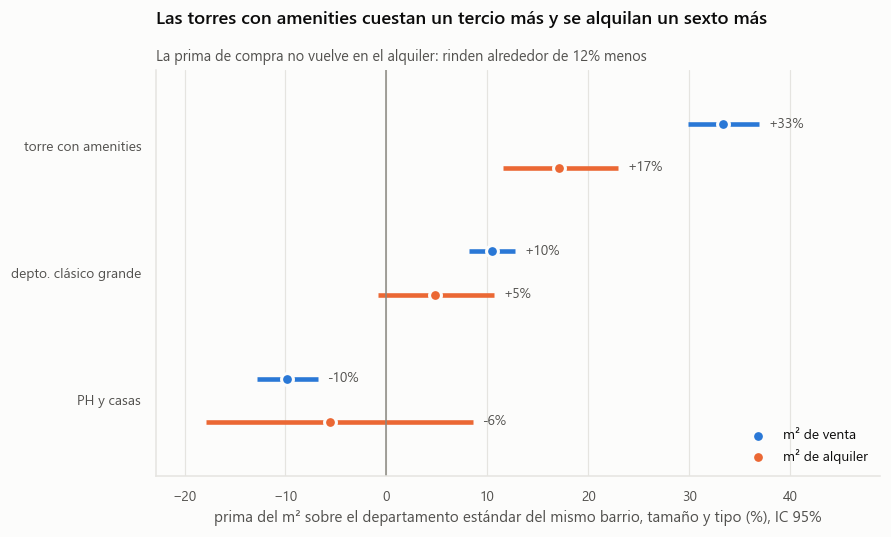

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
yy = np.arange(len(primas))[::-1] * 1.0
for desp, sufijo, color, nombre in [(0.17, "venta", eda.SERIE_1, "venta"), (-0.17, "alquiler", eda.SERIE_2, "alquiler")]:
    y_ = yy + desp
    ax.hlines(y_, primas[f"ic_inf_{sufijo}"], primas[f"ic_sup_{sufijo}"], color=color, linewidth=3)
    ax.scatter(primas[f"prima_pct_{sufijo}"], y_, s=60, color=color, edgecolor=eda.SUPERFICIE, linewidth=2,
               zorder=3, label=f"m² de {nombre}")
    for yv, (g, f) in zip(y_, primas.iterrows()):
        ax.annotate(f"{f[f'prima_pct_{sufijo}']:+.0f}%", (f[f"ic_sup_{sufijo}"], yv), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=eda.TINTA_2)
ax.axvline(0, color=eda.TINTA_3, linewidth=1)
ax.set_yticks(yy, [VISIBLE.get(g, g).replace("departamento", "depto.") for g in primas.index])
ax.set_ylim(-0.6, yy.max() + 0.6)
ax.set_xlim(min(primas["ic_inf_alquiler"].min(), primas["ic_inf_venta"].min()) - 5,
            max(primas["ic_sup_venta"].max(), primas["ic_sup_alquiler"].max()) + 12)
ax.set_xlabel("prima del m² sobre el departamento estándar del mismo barrio, tamaño y tipo (%), IC 95%")
ax.legend(loc="lower right")
eda.sin_grilla_y(ax)
eda.titulo(ax, "Las torres con amenities cuestan un tercio más y se alquilan un sexto más",
           "La prima de compra no vuelve en el alquiler: rinden alrededor de 12% menos")
eda.guardar(fig, 12, "micromercados_prima")
plt.show()

**Lectura.**

- **Torre con amenities: rinde menos, y es el resultado más firme.** En el mismo barrio
  y tamaño, el m² de venta cuesta alrededor de un tercio más que el del departamento
  estándar, y el alquiler sube alrededor de un sexto. Los dos intervalos están lejos de
  cero y no se tocan. La rentabilidad bruta queda alrededor de 12% más baja en términos
  relativos, cerca de 0,9 puntos.
- **Departamento clásico grande: rinde algo menos.** Cuesta alrededor de 10% más por m²
  y se alquila alrededor de 5% más, con un intervalo que roza el cero.
- **PH y casas: no se puede concluir del lado del alquiler.** Son más baratas por m²,
  pero hay muy pocos alquileres observados en el grupo y el intervalo es muy ancho.

**¿Es nuevo?** En parte. La 2da entrega ya había encontrado que las amenities restan
alrededor de medio punto de rentabilidad dentro del estrato. El micro-mercado precisa
ese hallazgo: lo que rinde menos es el **paquete** "edificio nuevo con amenities, a
estrenar, con cochera", y el efecto del paquete es mayor que el de la dummy de amenities
sola. Es coherente con H4: la antigüedad abarata más la compra que el alquiler.

## 5. ¿Mejoran el modelo de alquiler?

**Método.** El Ridge vigente contra tres variantes, con la misma validación cruzada del
notebook 03 (5 particiones, semillas 42, 7 y 2026). El PCA se ajusta **dentro** de cada
partición, para que no vea los alquileres que predice. Se usa el PCA y no el MCA porque
los dos dan los mismos ejes (sección 2) y el PCA entra en un pipeline de scikit-learn.

- **3 componentes en lugar de las 14 dummies**: ¿la síntesis reemplaza a las dummies?
- **vigente + 3 componentes**: ¿la síntesis agrega algo a las dummies?
- **vigente + micro-mercado**: ¿el grupo de la sección 3 agrega algo como categórica?
  Los grupos salen solo de los atributos, sin mirar el alquiler, así que no filtran la
  respuesta.
- **las 29 dummies**: la referencia de cuánta información hay en los atributos.

In [12]:
alq = M.preparar(df[(df["operacion"] == "alquiler") & df["alquiler_usd_mes"].notna()
                    & df["sup_total_m2"].notna() & df["barrio"].notna()]).reset_index(drop=True)
y = np.log(alq["alquiler_usd_mes"].values)


def ridge(dummies, componentes, con_grupo=False):
    categoricas = M.CATEGORICAS + (["micromercado"] if con_grupo else [])
    partes = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), M.NUMERICAS),
              ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categoricas)]
    if dummies:
        partes.append(("dum", "passthrough", dummies))
    if componentes:
        partes.append(("pca", Pipeline([("esc", StandardScaler()), ("pca", PCA(componentes))]), SI.ATRIBUTOS))
    return Pipeline([("pre", ColumnTransformer(partes)), ("mod", RidgeCV(alphas=np.logspace(-2, 3, 30)))])


variantes = {
    "vigente (14 dummies)": ridge(M.DUMMIES, 0),
    "3 componentes en lugar de las 14 dummies": ridge([], SI.N_EJES),
    "vigente + 3 componentes": ridge(M.DUMMIES, SI.N_EJES),
    "vigente + micro-mercado": ridge(M.DUMMIES, 0, con_grupo=True),
    "las 29 dummies": ridge(SI.ATRIBUTOS, 0),
}
columnas = list(dict.fromkeys(M.NUMERICAS + M.CATEGORICAS + ["micromercado"] + SI.ATRIBUTOS + M.DUMMIES))
filas = []
for semilla in [M.SEMILLA_CV, 7, 2026]:
    kf = KFold(M.N_FOLDS, shuffle=True, random_state=semilla)
    for nombre, modelo in variantes.items():
        pred = cross_val_predict(modelo, alq[columnas], y, cv=kf)
        filas.append({"variante": nombre, "semilla": semilla,
                      "r2": 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()})
r2 = pd.DataFrame(filas).pivot(index="variante", columns="semilla", values="r2").loc[list(variantes)]
r2["mejora minima vs vigente"] = (r2[[M.SEMILLA_CV, 7, 2026]] - r2.loc["vigente (14 dummies)", [M.SEMILLA_CV, 7, 2026]]).min(axis=1)
r2["pasa el criterio"] = r2["mejora minima vs vigente"] >= S.MEJORA_MINIMA_R2
print(f"Alquileres: {len(alq):,}. Criterio: mejora de {S.MEJORA_MINIMA_R2} en todas las semillas")
with pd.option_context("display.float_format", lambda x: f"{x:,.4f}"):
    display(r2)

Alquileres: 1,348. Criterio: mejora de 0.01 en todas las semillas


semilla,7,42,2026,mejora minima vs vigente,pasa el criterio
variante,,,,,
vigente (14 dummies),0.8466,0.8480,0.8459,0.0000,False
3 componentes en lugar de las 14 dummies,0.8396,0.8405,0.8388,-0.0075,False
vigente + 3 componentes,0.8533,0.8543,0.8518,0.0059,False
vigente + micro-mercado,0.8478,0.8488,0.8468,0.0008,False
las 29 dummies,0.8553,0.8562,0.8544,0.0082,False


**Lectura. Criterio 3: no se cumple.**

- **Los 3 componentes no reemplazan a las 14 dummies**: el modelo pierde R². La síntesis
  comprime, pero pierde justo la información que paga el alquiler (por ejemplo, amoblado
  o a reciclar, que no cargan fuerte en ninguno de los tres ejes).
- **Sumados a las dummies, mejoran poco**, debajo del umbral declarado.
- **El micro-mercado no agrega nada.** El grupo se arma con los mismos atributos que el
  modelo ya ve (dummies, tipo, superficie, antigüedad), así que no le dice nada nuevo.
- **Las 29 dummies tampoco pasan el umbral.** El techo de lo que los atributos del aviso
  pueden agregar al modelo es chico: el barrio y la superficie ya explican casi todo.

El Ridge se queda como está, igual que con las variables espaciales.

## Resumen: ¿vale la pena incorporarlo?

| Criterio | Resultado | ¿Se cumple? |
|---|---|---|
| 1. Los ejes se leen | Tres ejes con nombre claro: amenities y edificio nuevo, tamaño y categoría, PH o casa contra departamento. PCA y MCA coinciden | **Sí** |
| 2. Agregan algo a lo que ya hay | Cada eje repite una variable del dataset: `n_amenities`, la superficie y el tipo de propiedad | **No** |
| 3. Mejoran el modelo de alquiler | Ni los componentes ni el micro-mercado pasan el umbral; los componentes no reemplazan a las dummies | **No** |
| 4. Micro-mercados estables y que separan algo nuevo | Cuatro grupos muy estables, presentes dentro de casi todos los barrios. La torre con amenities rinde alrededor de 0,9 pp menos que el departamento estándar del mismo barrio y tamaño, medido con precios observados | **Sí** |

## La decisión: queda como análisis informativo, no entra al modelo

La síntesis de atributos y los micro-mercados **se conservan como análisis descriptivo**
de la oferta. **No se incorporan al modelo de alquiler**, y por lo tanto no cambian el
alquiler estimado, los KPIs ni el dataset analítico. Hay cuatro razones:

1. **No mejora la predicción.** Ninguna variante alcanza la mejora de 0,01 de R² en
   todas las semillas, que es el criterio declarado en `supuestos.MEJORA_MINIMA_R2` antes
   de comparar modelos. Es el mismo criterio que dejó afuera a las variables espaciales
   en el notebook 03, y se aplica igual acá.
2. **Reemplazar las dummies empeora el modelo.** Tres componentes en lugar de las 14
   dummies pierden R² en las tres semillas: la síntesis comprime los atributos, pero
   descarta justo los que el alquiler paga y no cargan en ningún eje, como amoblado o a
   reciclar.
3. **Se perdería la lectura de los coeficientes.** Cada coeficiente del Ridge se lee como
   cuánto paga el mercado por una característica concreta ("tener cochera suma tanto
   por ciento al alquiler"), y esa lectura es parte del producto para el inversor. Un
   componente mezcla doce dummies con pesos distintos: su coeficiente no tiene una
   lectura que el inversor pueda usar.
4. **No hay información nueva que agregar.** Los ejes repiten variables que el modelo ya
   tiene (el conteo de amenities, la superficie, el tipo), y el micro-mercado se arma
   con esas mismas variables. Por eso sumarlo no mueve el R².

**Lo que sí aporta, como análisis.** Confirma con dos métodos independientes que la
oferta se ordena por amenities, tamaño y tipo, y ofrece una forma legible de describirla
en cuatro micro-mercados. Su hallazgo, medido con precios observados y no con el modelo,
es que lo que rinde menos es el paquete "edificio nuevo con amenities", no solo la amenity:
la torre con amenities cuesta un tercio más por m² que un departamento estándar del mismo
barrio y tamaño, y se alquila solo un sexto más.